# Background

- **Author**: RUEI-HSIANG, CHANG（張睿庠，B12303030；AI協助）
- **Created At**: 2026-11-10
- **Research Motivation and Context (why are we interested in the findings?)：** 說明臺北、高雄既有G5／G6分群代表哪些候選人，以及年齡、來源性別、公開呈現學歷、登記政黨、城市與公職分布。採2026-11-08游智彬研究暫納入版210人；背景值與群別經唯一鍵連結，精確輸入`data/processed/tk_g5_g6_characteristics_20261110.csv`，見[資料文件](../data/processed/tk_g5_g6_characteristics_20261110_documentation.ipynb)。另讀4份11/08已保存的組合／K診斷／列序／納入敏感度CSV，精確路徑與SHA在讀檔格；其[上游文件](../data/processed/taipei_kaohsiung_yu_provisional_20261108_documentation.ipynb)與[原分群](taipei_kaohsiung_g5_g6_yu_provisional_20261108.ipynb)保留。本輪是既有群別的描述分析，不重新把G1–G4投入距離，也不更新官方參選資格。
- **Main Findings and Takeaways：** 主群P00／P01／P10／P11分別109／51／35／15人。P01女性30/51（58.8%）；P10無黨籍17/35（48.6%）。有年齡資料者平均依序53.4／48.5／47.2／36.6歲，但P10缺16/35、P11缺5/15，不能將觀察平均等同全群平均。學歷15筆屬搜尋未公開後歸最低類的政策碼；另列排除此旗標的描述，保留原碼。首長11人、議員199人分開呈現，兩市是同一合併分析下的地理分布。
- **Future Direction：** 優先補21個年齡及確認15個學歷政策碼；正式候選人資格更新後再依研究決定核對游智彬。若要探討策略、得票或當選結果，需另有結果資料與研究設計；本報告不推論因果或勝選機率。

執行狀態：本檔最後驗證格完成才代表本次描述分析已執行；輸出保存在本Notebook。資料固定為11/08快照，報告整理日期為11/10。

In [1]:
from pathlib import Path
import hashlib
import pandas as pd
from IPython.display import display, Markdown

def project_root():
    for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
        if (p/'AGENTS.md').is_file() and (p/'templates').is_dir(): return p
    raise FileNotFoundError('請從專案根目錄或其子目錄執行。')
ROOT=project_root()
def sha(p): return hashlib.sha256(Path(p).read_bytes()).hexdigest()
def checked_file(rel, expected):
    p=(ROOT/rel).resolve()
    assert p.is_relative_to((ROOT/'data/processed').resolve())
    assert p.is_file(), rel
    assert sha(p)==expected, f'輸入版本不同：{rel}'
    return p

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager
font_names={f.name for f in font_manager.fontManager.ttflist}
plt.rcParams['font.family']=next((f for f in ['Arial Unicode MS','Heiti TC','Noto Sans CJK TC','Noto Sans CJK SC'] if f in font_names),'DejaVu Sans')
plt.rcParams['axes.unicode_minus']=False
plt.rcParams['font.size']=11
plt.rcParams['savefig.dpi']=180
plt.rcParams['axes.spines.top']=False
plt.rcParams['axes.spines.right']=False

def table_md(frame):
    safe=frame.copy()
    for c in safe.select_dtypes(include=['object','string']).columns:
        safe[c]=safe[c].map(lambda x: x.replace('|','；') if isinstance(x,str) else x)
    return safe.to_markdown(index=False)
def show(title,frame):
    display(Markdown('**'+title+'**'))
    display(Markdown(table_md(frame)))
def share(n,total):
    return f'{n}/{total}（{100*n/total:.1f}%）' if total else '—（無觀測）'


In [2]:
PINS={'data/processed/tk_g5_g6_characteristics_20261110.csv': '9df3c70602e5ac1293422dfed1a4a008e07d7280b069225d30a3cb250000a8a0', 'data/processed/tk_g5_g6_yu_provisional_profiles_20261108.csv': '2890006e1552e9c58bd080100a9acbdf34e4f60ef7fbafe1e2bc29060b3d677b', 'data/processed/tk_g5_g6_yu_provisional_k_diagnostics_20261108.csv': '09bcf905cc1ba081c7721d8f43d1ad489b9fbb282306f14981aac0663221f7e9', 'data/processed/tk_g5_g6_yu_provisional_order_sensitivity_20261108.csv': '22c510e649aa342dea0d31322358ef87447f7f4d1cf0c1d60db927284bd81207', 'data/processed/tk_g5_g6_yu_provisional_inclusion_sensitivity_20261108.csv': 'a99b1991a56dfd915a868bd142b202f173915503c8fb9aedbf2f0f778d329c46'}
paths={rel:checked_file(rel,h) for rel,h in PINS.items()}
df=pd.read_csv(paths['data/processed/tk_g5_g6_characteristics_20261110.csv'],dtype=str,keep_default_na=False)
profiles=pd.read_csv(paths['data/processed/tk_g5_g6_yu_provisional_profiles_20261108.csv'])
diagnostics=pd.read_csv(paths['data/processed/tk_g5_g6_yu_provisional_k_diagnostics_20261108.csv'])
orders=pd.read_csv(paths['data/processed/tk_g5_g6_yu_provisional_order_sensitivity_20261108.csv'])
inclusion=pd.read_csv(paths['data/processed/tk_g5_g6_yu_provisional_inclusion_sensitivity_20261108.csv'])
assert df.shape==(210,53) and df.candidate_key.is_unique
assert df.cluster_profile_id.eq('P'+df.G5_first_time_any_elected_office+df.G6_political_family).all()
assert df.G5_first_time_any_elected_office.isin(['0','1']).all()
assert df.G6_political_family.isin(['0','1']).all()
assert df.county_city.value_counts().to_dict()=={'高雄市':106,'臺北市':104}
assert df.office_type.value_counts().to_dict()=={'直轄市議員':199,'直轄市長':11}
assert set(df.G2_sex)=={'男','女'}
assert set(df.G3_education_level)=={'大學以下','大學','研究所'}
assert set(df.G4_party)=={'國民黨','民進黨','民眾黨','其他政黨','無黨籍／未經政黨推薦'}
# Only simple, explicitly documented analysis/display variables are derived here.
df['age']=pd.to_numeric(df.G1_age_2026_minus_birth_year.replace('',pd.NA),errors='raise').astype(float)
df['education_display']=df.G3_education_level.where(df.G3_unpublished_lowest_flag!='1','未公開（政策碼）')
GROUPS=['P00','P01','P10','P11']
LABELS={'P00':'曾參選／未發現符合親屬','P01':'曾參選／有符合公職親屬','P10':'首次參選／未發現符合親屬','P11':'首次參選／有符合公職親屬'}
COLORS={'P00':'#4477AA','P01':'#EE6677','P10':'#228833','P11':'#AA3377'}
POOLS={'all':df,'mayor':df[df.office_type=='直轄市長'],'council':df[df.office_type=='直轄市議員']}
POOL_LABELS={'all':'兩市合併','mayor':'首長','council':'議員'}
assert set(POOLS['mayor'].candidate_key).isdisjoint(set(POOLS['council'].candidate_key))
assert set(POOLS['mayor'].candidate_key)|set(POOLS['council'].candidate_key)==set(df.candidate_key)
for pool,x in POOLS.items():
    counts=x.cluster_profile_id.value_counts().reindex(GROUPS,fill_value=0)
    old=profiles[profiles.pool==pool].set_index('profile_id').loc[GROUPS,'n']
    assert counts.tolist()==old.tolist()
show('表1：已連結前10位候選人；整體N=210，識別欄不參與分群',
     df[['candidate_name','county_city','office_type','cluster_profile_id','age','G2_sex','G3_education_level','G4_party']].head(10)
     .rename(columns={'candidate_name':'姓名','county_city':'城市','office_type':'公職','cluster_profile_id':'主群','age':'年齡（歲）','G2_sex':'來源性別','G3_education_level':'公開學歷分類','G4_party':'登記政黨'}).fillna('缺值'))


**表1：已連結前10位候選人；整體N=210，識別欄不參與分群**

| 姓名   | 城市   | 公職     | 主群   |   年齡（歲） | 來源性別   | 公開學歷分類   | 登記政黨             |
|:-------|:-------|:---------|:-------|-------------:|:-----------|:---------------|:---------------------|
| 郭璽   | 臺北市 | 直轄市長 | P00    |           68 | 男         | 大學           | 其他政黨             |
| 沈伯洋 | 臺北市 | 直轄市長 | P01    |           44 | 男         | 研究所         | 民進黨               |
| 蕭文乾 | 臺北市 | 直轄市長 | P00    |           52 | 男         | 研究所         | 其他政黨             |
| 唐新民 | 臺北市 | 直轄市長 | P00    |           76 | 男         | 研究所         | 其他政黨             |
| 蔣萬安 | 臺北市 | 直轄市長 | P01    |           48 | 男         | 研究所         | 國民黨               |
| 林志成 | 臺北市 | 直轄市長 | P00    |           61 | 男         | 研究所         | 無黨籍／未經政黨推薦 |
| 張靜   | 高雄市 | 直轄市長 | P00    |           70 | 男         | 大學           | 其他政黨             |
| 賴瑞隆 | 高雄市 | 直轄市長 | P00    |           53 | 男         | 研究所         | 民進黨               |
| 王肇民 | 高雄市 | 直轄市長 | P10    |           63 | 男         | 大學           | 無黨籍／未經政黨推薦 |
| 柯志恩 | 高雄市 | 直轄市長 | P01    |           64 | 女         | 研究所         | 國民黨               |

## 分析前變數摘要

所有分析用欄位先列摘要。年齡為2026減出生年或上游保留的報導年齡代理值，未據此新推完整生日；有效189、缺21。類別比例的分母為該欄全部非空白觀測，缺值另列；超過十類只顯示前十類，比例不以這十類的小計為分母。候選人鍵、姓名、選區與來源網址是識別／追溯欄，不當作數值或解釋變數分析。年齡來源、來源衝突、G5查核狀態及G6搜尋狀態作資料品質描述。

In [3]:
a=df.age.dropna()
numeric_summary=pd.DataFrame([{'變數':'年齡（歲）','樣本N':len(df),'有效N':len(a),'缺值N':df.age.isna().sum(),
 '平均':a.mean(),'最小':a.min(),'第25百分位':a.quantile(.25),'中位數':a.median(),'第75百分位':a.quantile(.75),'最大':a.max(),'標準差':a.std(ddof=1)}]).round(2)
show('表2：數值變數完整摘要（N=210）',numeric_summary)
CAT_LABELS={'cluster_profile_id':'G5/G6主群','G5_first_time_any_elected_office':'首次參選G5','G6_political_family':'符合範圍公職親屬G6',
'county_city':'城市','office_type':'公職類型','G2_sex':'來源性別','G3_education_level':'公開學歷分類','G4_party':'登記政黨',
'G3_unpublished_lowest_flag':'學歷未公開政策旗標','education_display':'圖中學歷（政策碼另列）',
'eligibility_provisional_flag_20261108':'資格爭議研究暫納入旗標','G1_source_tier':'年齡來源層級',
'G1_estimation_flag_tk_20261108':'兩市年齡代理新增旗標','source_conflict_flag':'來源衝突旗標',
'G5_audit_status':'G5查核狀態','G6_search_status_20261108':'G6搜尋狀態'}
cat_rows=[]
for c,label in CAT_LABELS.items():
    valid=df[c].ne('');n=int(valid.sum());missing=int((~valid).sum())
    for val,count in df.loc[valid,c].value_counts().head(10).items():
        cat_rows.append({'變數':label,'有效N':n,'缺值N':missing,'類別':val,'人數':int(count),'有效觀測%':round(100*count/n,2)})
cat_summary=pd.DataFrame(cat_rows)
show('表3：類別摘要（總N=210；各欄有效N及缺值N另列，最多十類）',cat_summary)
assert df.age.isna().sum()==21
assert df.loc[df.age.isna(),'G5_first_time_any_elected_office'].eq('1').all()
assert df.G3_unpublished_lowest_flag.eq('1').sum()==15


**表2：數值變數完整摘要（N=210）**

| 變數       |   樣本N |   有效N |   缺值N |   平均 |   最小 |   第25百分位 |   中位數 |   第75百分位 |   最大 |   標準差 |
|:-----------|--------:|--------:|--------:|-------:|-------:|-------------:|---------:|-------------:|-------:|---------:|
| 年齡（歲） |     210 |     189 |      21 |  50.53 |     24 |           42 |       49 |           59 |     83 |     11.9 |

**表3：類別摘要（總N=210；各欄有效N及缺值N另列，最多十類）**

| 變數                   |   有效N |   缺值N | 類別                                                    |   人數 |   有效觀測% |
|:-----------------------|--------:|--------:|:--------------------------------------------------------|-------:|------------:|
| G5/G6主群              |     210 |       0 | P00                                                     |    109 |       51.9  |
| G5/G6主群              |     210 |       0 | P01                                                     |     51 |       24.29 |
| G5/G6主群              |     210 |       0 | P10                                                     |     35 |       16.67 |
| G5/G6主群              |     210 |       0 | P11                                                     |     15 |        7.14 |
| 首次參選G5             |     210 |       0 | 0                                                       |    160 |       76.19 |
| 首次參選G5             |     210 |       0 | 1                                                       |     50 |       23.81 |
| 符合範圍公職親屬G6     |     210 |       0 | 0                                                       |    144 |       68.57 |
| 符合範圍公職親屬G6     |     210 |       0 | 1                                                       |     66 |       31.43 |
| 城市                   |     210 |       0 | 高雄市                                                  |    106 |       50.48 |
| 城市                   |     210 |       0 | 臺北市                                                  |    104 |       49.52 |
| 公職類型               |     210 |       0 | 直轄市議員                                              |    199 |       94.76 |
| 公職類型               |     210 |       0 | 直轄市長                                                |     11 |        5.24 |
| 來源性別               |     210 |       0 | 男                                                      |    129 |       61.43 |
| 來源性別               |     210 |       0 | 女                                                      |     81 |       38.57 |
| 公開學歷分類           |     210 |       0 | 研究所                                                  |    125 |       59.52 |
| 公開學歷分類           |     210 |       0 | 大學                                                    |     53 |       25.24 |
| 公開學歷分類           |     210 |       0 | 大學以下                                                |     32 |       15.24 |
| 登記政黨               |     210 |       0 | 國民黨                                                  |     71 |       33.81 |
| 登記政黨               |     210 |       0 | 民進黨                                                  |     63 |       30    |
| 登記政黨               |     210 |       0 | 無黨籍／未經政黨推薦                                    |     47 |       22.38 |
| 登記政黨               |     210 |       0 | 其他政黨                                                |     22 |       10.48 |
| 登記政黨               |     210 |       0 | 民眾黨                                                  |      7 |        3.33 |
| 學歷未公開政策旗標     |     210 |       0 | 0                                                       |    195 |       92.86 |
| 學歷未公開政策旗標     |     210 |       0 | 1                                                       |     15 |        7.14 |
| 圖中學歷（政策碼另列） |     210 |       0 | 研究所                                                  |    125 |       59.52 |
| 圖中學歷（政策碼另列） |     210 |       0 | 大學                                                    |     53 |       25.24 |
| 圖中學歷（政策碼另列） |     210 |       0 | 大學以下                                                |     17 |        8.1  |
| 圖中學歷（政策碼另列） |     210 |       0 | 未公開（政策碼）                                        |     15 |        7.14 |
| 資格爭議研究暫納入旗標 |     210 |       0 | 0                                                       |    209 |       99.52 |
| 資格爭議研究暫納入旗標 |     210 |       0 | 1                                                       |      1 |        0.48 |
| 年齡來源層級           |     189 |      21 | prior_evidence_retained                                 |    124 |       65.61 |
| 年齡來源層級           |     189 |      21 | secondary_wikipedia_explicit_birth_date                 |     15 |        7.94 |
| 年齡來源層級           |     189 |      21 | supplement_cec_record_identity_confirmed                |     14 |        7.41 |
| 年齡來源層級           |     189 |      21 | supplement_source_rule                                  |     10 |        5.29 |
| 年齡來源層級           |     189 |      21 | reported_age_proxy_pm1                                  |      6 |        3.17 |
| 年齡來源層級           |     189 |      21 | supplement_age_from_report                              |      6 |        3.17 |
| 年齡來源層級           |     189 |      21 | cec_historical_with_identity_check                      |      4 |        2.12 |
| 年齡來源層級           |     189 |      21 | media_2026_explicit_birth_date                          |      2 |        1.06 |
| 年齡來源層級           |     189 |      21 | supplement_cec_record_same_district_name_match          |      2 |        1.06 |
| 年齡來源層級           |     189 |      21 | media_full_text                                         |      2 |        1.06 |
| 兩市年齡代理新增旗標   |       6 |     204 | reported_age_birth_year_pm1                             |      6 |      100    |
| 來源衝突旗標           |     210 |       0 | 0                                                       |    209 |       99.52 |
| 來源衝突旗標           |     210 |       0 | 0; explicit_birth_year_vs_reported_age                  |      1 |        0.48 |
| G5查核狀態             |     210 |       0 | official_historical_record_located_identity_supported   |    123 |       58.57 |
| G5查核狀態             |     210 |       0 | yang_revised_rule_G5_no_prior_cec_record_rule_20261104  |     38 |       18.1  |
| G5查核狀態             |     210 |       0 | yang_revised_rule_cec_record_identity_confirmed         |     19 |        9.05 |
| G5查核狀態             |     210 |       0 | explicit_first_time_report_not_exhaustive_archive_proof |      5 |        2.38 |
| G5查核狀態             |     210 |       0 | yang_revised_rule_source_rule                           |      5 |        2.38 |
| G5查核狀態             |     210 |       0 | historical_identity_checked_20261108                    |      5 |        2.38 |
| G5查核狀態             |     210 |       0 | secondary_prior_elected_office_located                  |      3 |        1.43 |
| G5查核狀態             |     210 |       0 | official_bulletin_saved_text_rechecked                  |      2 |        0.95 |
| G5查核狀態             |     210 |       0 | candidate_declared_prior_election_text_rechecked        |      2 |        0.95 |
| G5查核狀態             |     210 |       0 | yang_revised_rule_cec_record_same_district_name_match   |      2 |        0.95 |
| G6搜尋狀態             |     210 |       0 | searched_no_qualifying_evidence                         |    143 |       68.1  |
| G6搜尋狀態             |     210 |       0 | positive_full_text                                      |     39 |       18.57 |
| G6搜尋狀態             |     210 |       0 | positive_evidence_retained                              |     26 |       12.38 |
| G6搜尋狀態             |     210 |       0 | none_found_online_screen                                |      1 |        0.48 |
| G6搜尋狀態             |     210 |       0 | positive_current_full_text                              |      1 |        0.48 |

### The actual analysis starts below

## 1. 分群定義與三個樣本池

G5=1按既定楊修訂規則編為首次參選任何民選公職；G5=0表示曾參選，包含未當選紀錄，不等同現任或曾當選。G6=1表示有符合配偶／三親等內血姻親與民選／政治任命公職範圍的證據；G6=0表示已記錄搜尋未發現符合證據，不是不存在任何政治人物親戚。一般軍職、常任文官不計入。

原方法為兩個二元欄位等權重對稱Gower類別距離（本題等同Hamming）、平均連結法、距離0切樹。主群因此就是觀察到的G5/G6組合。G1–G4只描述群內特徵，不能反過來稱它們是分群依據。

**表4：主群人數與池內占比（合併210=首長11+議員199；三池不得重複相加）**

| 主群   | 背景組合                 | 兩市合併 N=210   | 首長 N=11     | 議員 N=199       |
|:-------|:-------------------------|:-----------------|:--------------|:-----------------|
| P00    | 曾參選／未發現符合親屬   | 109/210（51.9%） | 6/11（54.5%） | 103/199（51.8%） |
| P01    | 曾參選／有符合公職親屬   | 51/210（24.3%）  | 3/11（27.3%） | 48/199（24.1%）  |
| P10    | 首次參選／未發現符合親屬 | 35/210（16.7%）  | 2/11（18.2%） | 33/199（16.6%）  |
| P11    | 首次參選／有符合公職親屬 | 15/210（7.1%）   | 0/11（0.0%）  | 15/199（7.5%）   |

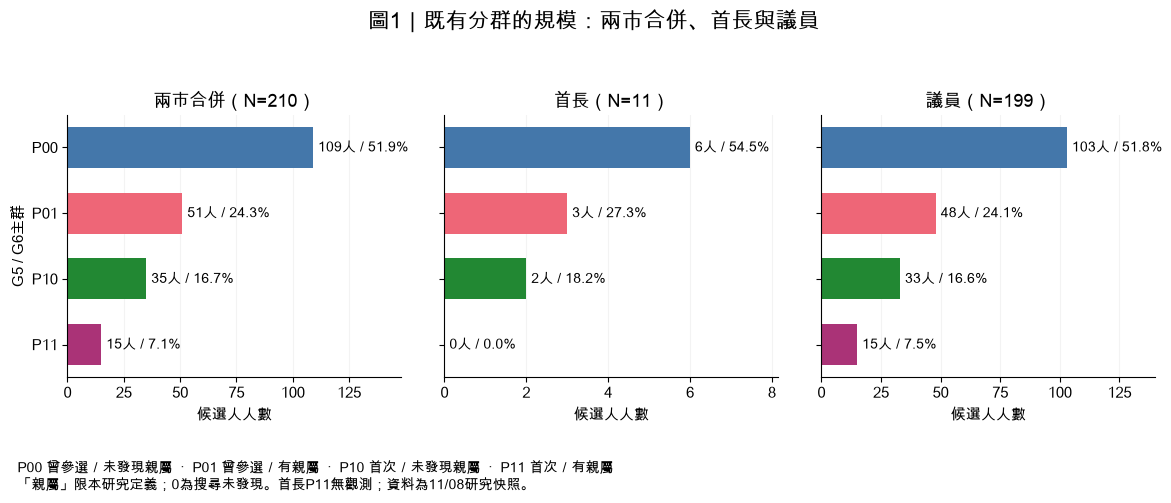

In [4]:
count_rows=[]
for g in GROUPS:
    row={'主群':g,'背景組合':LABELS[g]}
    for pool,x in POOLS.items():row[f'{POOL_LABELS[pool]} N={len(x)}']=share(int(x.cluster_profile_id.eq(g).sum()),len(x))
    count_rows.append(row)
count_table=pd.DataFrame(count_rows)
show('表4：主群人數與池內占比（合併210=首長11+議員199；三池不得重複相加）',count_table)
ASSETS=ROOT/'finding/taipei_kaohsiung_cluster_characteristics_20261110_assets'
ASSETS.mkdir(exist_ok=True)
fig,axes=plt.subplots(1,3,figsize=(12,5.0),sharey=True)
for ax,(pool,x) in zip(axes,POOLS.items()):
    vals=x.cluster_profile_id.value_counts().reindex(GROUPS,fill_value=0)
    ax.barh(GROUPS,vals,color=[COLORS[g] for g in GROUPS],height=.62)
    ax.set_xlim(0,vals.max()*1.36)
    for i,n in enumerate(vals):ax.text(n+.02*vals.max(),i,f'{n}人 / {100*n/len(x):.1f}%',va='center',fontsize=10)
    ax.set_title(f'{POOL_LABELS[pool]}（N={len(x)}）',fontsize=13)
    ax.set_xlabel('候選人人數');ax.grid(axis='x',alpha=.15);ax.set_axisbelow(True)
axes[0].invert_yaxis();axes[0].set_ylabel('G5 / G6主群')
fig.suptitle('圖1｜既有分群的規模：兩市合併、首長與議員',fontsize=16)
fig.text(.02,.02,'P00 曾參選／未發現親屬  ·  P01 曾參選／有親屬  ·  P10 首次／未發現親屬  ·  P11 首次／有親屬\n「親屬」限本研究定義；0為搜尋未發現。首長P11無觀測；資料為11/08研究快照。',fontsize=10)
fig.tight_layout(rect=(0,.12,1,.93));fig.savefig(ASSETS/'profile_sizes.png',bbox_inches='tight');plt.show();plt.close(fig)


合併池P00占51.9%，是最大群；P11占7.1%，是最小群。議員占合併樣本199/210（94.8%），因此合併結果主要反映議員候選人。首長只有三個非空組合，P11=0是樣本中未出現，不是遺漏群別。

## 2. 各群年齡、性別與公開學歷

下列各表的類別比例以各群全體為分母，因來源性別、學歷編碼、政黨與城市無空白；年齡僅使用有值者，另列有效N、缺值與分布。這裡是四群描述，不做事後挑選的兩兩顯著性檢定。

**表5：各群年齡完整摘要（整體N=210；年齡有效N=189）**

| 主群   |   群人數 |   年齡有效N |   年齡缺值N |   平均歲數 |   標準差 |   中位數 |   最小 |   第25百分位 |   第75百分位 |   最大 |
|:-------|---------:|------------:|------------:|-----------:|---------:|---------:|-------:|-------------:|-------------:|-------:|
| P00    |      109 |         109 |           0 |      53.37 |    11.75 |     53   |     28 |         44   |        64    |     77 |
| P01    |       51 |          51 |           0 |      48.45 |     8.76 |     47   |     31 |         42.5 |        55    |     73 |
| P10    |       35 |          19 |          16 |      47.21 |    14.71 |     48   |     26 |         36.5 |        57    |     83 |
| P11    |       15 |          10 |           5 |      36.6  |     9.11 |     36.5 |     24 |         31   |        41.25 |     55 |

**表6：合併池各群其他特徵（N=210；類別為人數／全群人數及百分比）**

| 主群   |   人數 | 平均年齡（有效N）   | 女性            | 公開研究所類    | 學歷政策碼     |
|:-------|-------:|:--------------------|:----------------|:----------------|:---------------|
| P00    |    109 | 53.4（109/109）     | 37/109（33.9%） | 69/109（63.3%） | 1/109（0.9%）  |
| P01    |     51 | 48.5（51/51）       | 30/51（58.8%）  | 34/51（66.7%）  | 0/51（0.0%）   |
| P10    |     35 | 47.2（19/35）       | 9/35（25.7%）   | 13/35（37.1%）  | 10/35（28.6%） |
| P11    |     15 | 36.6（10/15）       | 5/15（33.3%）   | 9/15（60.0%）   | 4/15（26.7%）  |

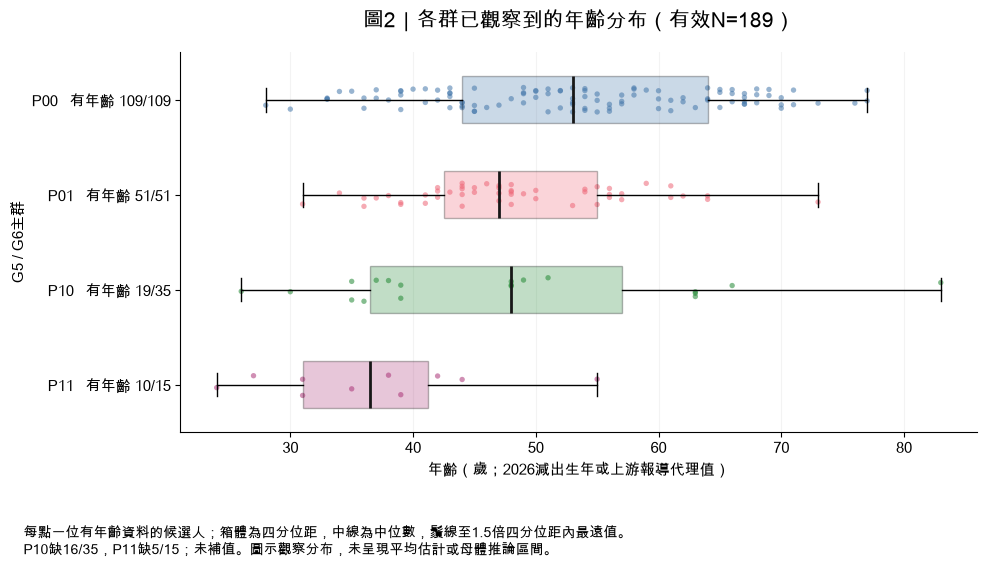

In [5]:
def age_stats(x):
    out=[]
    for g in GROUPS:
        z=x[x.cluster_profile_id==g];v=z.age.dropna()
        if len(z)==0:continue
        out.append({'主群':g,'群人數':len(z),'年齡有效N':len(v),'年齡缺值N':len(z)-len(v),
                    '平均歲數':v.mean(),'標準差':v.std(ddof=1),'中位數':v.median(),
                    '最小':v.min(),'第25百分位':v.quantile(.25),'第75百分位':v.quantile(.75),'最大':v.max()})
    return pd.DataFrame(out).round(2)
age_table=age_stats(df)
show('表5：各群年齡完整摘要（整體N=210；年齡有效N=189）',age_table)
def overview(x):
    rows=[]
    for g in GROUPS:
        z=x[x.cluster_profile_id==g];n=len(z);a=z.age.dropna()
        if not n:continue
        rows.append({'主群':g,'人數':n,'平均年齡（有效N）':f'{a.mean():.1f}（{len(a)}/{n}）' if len(a) else '無年齡資料',
        '女性':share(int(z.G2_sex.eq('女').sum()),n),
        '公開研究所類':share(int(z.G3_education_level.eq('研究所').sum()),n),
        '學歷政策碼':share(int(z.G3_unpublished_lowest_flag.eq('1').sum()),n)})
    return pd.DataFrame(rows)
overview_all=overview(df)
show('表6：合併池各群其他特徵（N=210；類別為人數／全群人數及百分比）',overview_all)
fig,ax=plt.subplots(figsize=(10,5.7))
rng=np.random.default_rng(20261110)
vals=[df.loc[df.cluster_profile_id==g,'age'].dropna().to_numpy() for g in GROUPS]
bp=ax.boxplot(vals,orientation='horizontal',patch_artist=True,widths=.5,showfliers=False,medianprops={'color':'#171717','linewidth':2})
for box,g in zip(bp['boxes'],GROUPS):box.set_facecolor(COLORS[g]);box.set_alpha(.28)
for i,(v,g) in enumerate(zip(vals,GROUPS),1):
    ax.scatter(v,i+rng.uniform(-.13,.13,len(v)),color=COLORS[g],s=15,alpha=.55,edgecolors='none')
ax.set_yticks(range(1,5),[f'{g}   有年齡 {len(v)}/{int(df.cluster_profile_id.eq(g).sum())}' for g,v in zip(GROUPS,vals)])
ax.invert_yaxis();ax.set_xlabel('年齡（歲；2026減出生年或上游報導代理值）');ax.set_ylabel('G5 / G6主群')
ax.set_title('圖2｜各群已觀察到的年齡分布（有效N=189）',pad=18,fontsize=15)
ax.grid(axis='x',alpha=.15);ax.set_axisbelow(True)
fig.text(.03,.015,'每點一位有年齡資料的候選人；箱體為四分位距，中線為中位數，鬚線至1.5倍四分位距內最遠值。\nP10缺16/35，P11缺5/15；未補值。圖示觀察分布，未呈現平均估計或母體推論區間。',fontsize=10)
fig.tight_layout(rect=(0,.12,1,1));fig.savefig(ASSETS/'age_distribution.png',bbox_inches='tight');plt.show();plt.close(fig)


P01女性占30/51（58.8%），為四群最高。P00有年齡資料109人，平均53.4歲；P11僅10人有年齡，觀察平均36.6歲。P10與P11分別缺45.7%及33.3%年齡；缺值集中於首次參選者，因此只能說「已觀察資料中較年輕」，不能替缺值者補上這個平均或據此斷定政治家族導致提早參選。

年齡來源兼有歷史資料、出生年及報導代理值，並非一律精確足歲。上游保留鄧巧佩的明載出生年與報導年齡衝突旗標，本輪未自行消除。

**表7：各群登記政黨（N=210；分母為各群全體）**

| 主群   |   群人數 | 國民黨          | 民進黨          | 民眾黨        | 其他政黨        | 無黨籍／未經政黨推薦   |
|:-------|---------:|:----------------|:----------------|:--------------|:----------------|:-----------------------|
| P00    |      109 | 34/109（31.2%） | 35/109（32.1%） | 5/109（4.6%） | 15/109（13.8%） | 20/109（18.3%）        |
| P01    |       51 | 27/51（52.9%）  | 16/51（31.4%）  | 1/51（2.0%）  | 1/51（2.0%）    | 6/51（11.8%）          |
| P10    |       35 | 6/35（17.1%）   | 7/35（20.0%）   | 0/35（0.0%）  | 5/35（14.3%）   | 17/35（48.6%）         |
| P11    |       15 | 4/15（26.7%）   | 5/15（33.3%）   | 1/15（6.7%）  | 1/15（6.7%）    | 4/15（26.7%）          |

**表8：各群公開呈現學歷原編碼（N=210；含15筆未公開歸最低類政策碼）**

| 主群   |   群人數 | 大學以下        | 大學            | 研究所          |
|:-------|---------:|:----------------|:----------------|:----------------|
| P00    |      109 | 12/109（11.0%） | 28/109（25.7%） | 69/109（63.3%） |
| P01    |       51 | 3/51（5.9%）    | 14/51（27.5%）  | 34/51（66.7%）  |
| P10    |       35 | 13/35（37.1%）  | 9/35（25.7%）   | 13/35（37.1%）  |
| P11    |       15 | 4/15（26.7%）   | 2/15（13.3%）   | 9/15（60.0%）   |

**表9：僅排除學歷政策碼後的描述（教育有效N=195；不刪除分群樣本、不改原G3）**

| 主群   |   原群N |   政策碼人數 |   非政策碼N | 大學以下（非政策碼）   | 大學（非政策碼）   | 研究所（非政策碼）   |
|:-------|--------:|-------------:|------------:|:-----------------------|:-------------------|:---------------------|
| P00    |     109 |            1 |         108 | 11/108（10.2%）        | 28/108（25.9%）    | 69/108（63.9%）      |
| P01    |      51 |            0 |          51 | 3/51（5.9%）           | 14/51（27.5%）     | 34/51（66.7%）       |
| P10    |      35 |           10 |          25 | 3/25（12.0%）          | 9/25（36.0%）      | 13/25（52.0%）       |
| P11    |      15 |            4 |          11 | 0/11（0.0%）           | 2/11（18.2%）      | 9/11（81.8%）        |

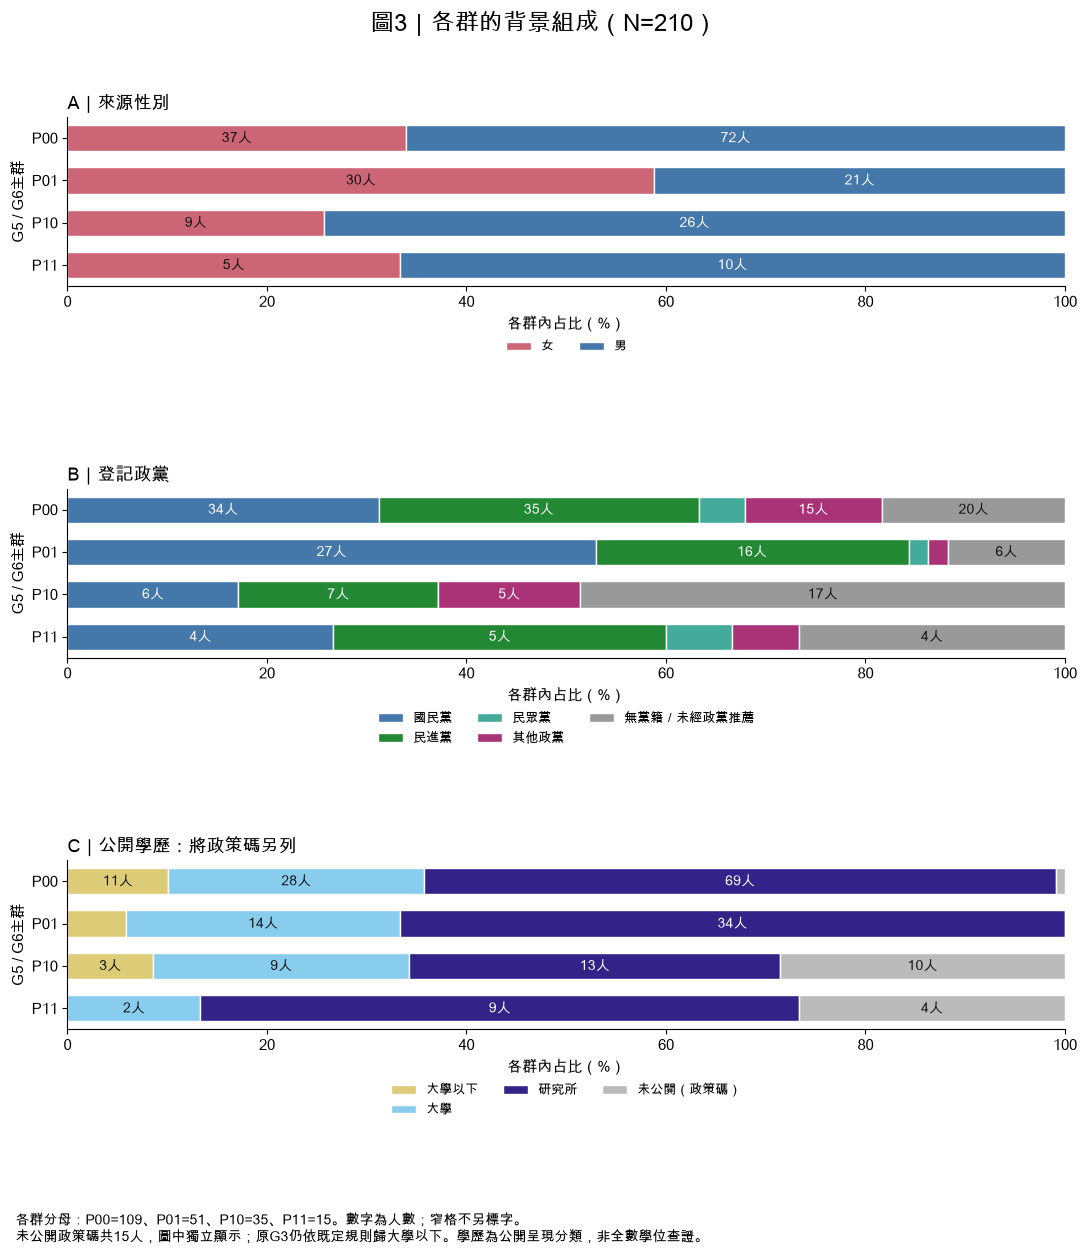

In [6]:
PARTIES=['國民黨','民進黨','民眾黨','其他政黨','無黨籍／未經政黨推薦']
EDUCATION=['大學以下','大學','研究所']
def categorical_table(x,col,cats):
    rows=[]
    for g in GROUPS:
        z=x[x.cluster_profile_id==g];n=len(z)
        if not n:continue
        r={'主群':g,'群人數':n}
        for v in cats:r[v]=share(int(z[col].eq(v).sum()),n)
        rows.append(r)
    return pd.DataFrame(rows)
party_table=categorical_table(df,'G4_party',PARTIES)
edu_table=categorical_table(df,'G3_education_level',EDUCATION)
sex_table=categorical_table(df,'G2_sex',['女','男'])
show('表7：各群登記政黨（N=210；分母為各群全體）',party_table)
show('表8：各群公開呈現學歷原編碼（N=210；含15筆未公開歸最低類政策碼）',edu_table)
sensitivity_rows=[]
for g in GROUPS:
    z=df[df.cluster_profile_id==g];q=z[z.G3_unpublished_lowest_flag!='1']
    sensitivity_rows.append({'主群':g,'原群N':len(z),'政策碼人數':len(z)-len(q),'非政策碼N':len(q),
                            '大學以下（非政策碼）':share(int(q.G3_education_level.eq('大學以下').sum()),len(q)),
                            '大學（非政策碼）':share(int(q.G3_education_level.eq('大學').sum()),len(q)),
                            '研究所（非政策碼）':share(int(q.G3_education_level.eq('研究所').sum()),len(q))})
edu_sensitivity=pd.DataFrame(sensitivity_rows)
show('表9：僅排除學歷政策碼後的描述（教育有效N=195；不刪除分群樣本、不改原G3）',edu_sensitivity)
fig,axes=plt.subplots(3,1,figsize=(11,12.5))
settings=[('G2_sex',['女','男'],['#CC6677','#4477AA'],'A｜來源性別'),
          ('G4_party',PARTIES,['#4477AA','#228833','#44AA99','#AA3377','#999999'],'B｜登記政黨'),
          ('education_display',['大學以下','大學','研究所','未公開（政策碼）'],['#DDCC77','#88CCEE','#332288','#BBBBBB'],'C｜公開學歷：將政策碼另列')]
for ax,(col,cats,colors,title) in zip(axes,settings):
    left=np.zeros(4)
    sizes=np.array([int(df.cluster_profile_id.eq(g).sum()) for g in GROUPS])
    for category,color in zip(cats,colors):
        n=np.array([int(((df.cluster_profile_id==g)&(df[col]==category)).sum()) for g in GROUPS])
        pct=n/sizes*100
        bars=ax.barh(GROUPS,pct,left=left,label=category,color=color,height=.62,edgecolor='white')
        for i,(count,width,start) in enumerate(zip(n,pct,left)):
            if width>=7:ax.text(start+width/2,i,f'{count}人',ha='center',va='center',fontsize=10,color='white' if color in ['#332288','#4477AA','#228833','#AA3377'] else '#111111')
        left+=pct
    assert np.allclose(left,100)
    ax.set_xlim(0,100);ax.invert_yaxis();ax.set_xlabel('各群內占比（%）');ax.set_ylabel('G5 / G6主群')
    ax.set_title(title,loc='left',fontsize=13);ax.legend(loc='upper center',bbox_to_anchor=(.5,-.25),ncol=3,frameon=False,fontsize=9)
fig.suptitle('圖3｜各群的背景組成（N=210）',fontsize=17,y=.99)
fig.text(.02,.005,'各群分母：P00=109、P01=51、P10=35、P11=15。數字為人數；窄格不另標字。\n未公開政策碼共15人，圖中獨立顯示；原G3仍依既定規則歸大學以下。學歷為公開呈現分類，非全數學位查證。',fontsize=10)
fig.tight_layout(rect=(0,.065,1,.97),h_pad=3.8);fig.savefig(ASSETS/'characteristic_composition.png',bbox_inches='tight');plt.show();plt.close(fig)


P00的國民黨34人、民進黨35人，兩黨人數接近；P01國民黨占27/51（52.9%）；P10無黨籍／未經政黨推薦占17/35（48.6%）。這是群內組成，不是各黨所有候選人進入該群的比例。

P10原「大學以下」13人中有10筆是未公開政策碼；P11的4筆「大學以下」全部為政策碼。不能因此把這兩群形容成低學歷群。排除政策碼後，P10公開研究所類為13/25（52.0%），P11為9/11（81.8%）；這些比例只描述有可採公開資訊者，不代替全群真實學歷。

## 3. 城市與公職分布

兩市仍是同一個合併池；以下按城市查看既有群別的組成，未重新各市分群。首長與議員則保留既有的兩個公職池。

In [7]:
city_rows=[]
for city in ['臺北市','高雄市']:
    x=df[df.county_city==city];r={'城市':city,'候選人N':len(x)}
    r.update({g:share(int(x.cluster_profile_id.eq(g).sum()),len(x)) for g in GROUPS});city_rows.append(r)
city_table=pd.DataFrame(city_rows)
show('表10：城市內各群組成（臺北N=104、高雄N=106；分母為各市全體）',city_table)
council_overview=overview(POOLS['council'])
show('表11：議員池各群特徵（N=199；年齡有效N=178）',council_overview)
council_ages=age_stats(POOLS['council'])
show('表12：議員池年齡完整摘要（N=199；缺21）',council_ages)
mayor_cols=['candidate_name','county_city','cluster_profile_id','age','G2_sex','G3_education_level','G4_party']
mayor_table=POOLS['mayor'].sort_values(['cluster_profile_id','county_city','candidate_key'])[mayor_cols].rename(columns={
 'candidate_name':'姓名','county_city':'城市','cluster_profile_id':'主群','age':'年齡（歲）','G2_sex':'來源性別','G3_education_level':'公開學歷分類','G4_party':'登記政黨'})
show('表13：首長11人逐人特徵（11/08研究名冊；本輪未更新官方資格）',mayor_table)
show('表14：首長池年齡完整摘要（N=11；三群6／3／2人，僅作描述）',age_stats(POOLS['mayor']))


**表10：城市內各群組成（臺北N=104、高雄N=106；分母為各市全體）**

| 城市   |   候選人N | P00             | P01             | P10             | P11           |
|:-------|----------:|:----------------|:----------------|:----------------|:--------------|
| 臺北市 |       104 | 55/104（52.9%） | 21/104（20.2%） | 21/104（20.2%） | 7/104（6.7%） |
| 高雄市 |       106 | 54/106（50.9%） | 30/106（28.3%） | 14/106（13.2%） | 8/106（7.5%） |

**表11：議員池各群特徵（N=199；年齡有效N=178）**

| 主群   |   人數 | 平均年齡（有效N）   | 女性            | 公開研究所類    | 學歷政策碼     |
|:-------|-------:|:--------------------|:----------------|:----------------|:---------------|
| P00    |    103 | 52.8（103/103）     | 37/103（35.9%） | 65/103（63.1%） | 1/103（1.0%）  |
| P01    |     48 | 48.2（48/48）       | 29/48（60.4%）  | 31/48（64.6%）  | 0/48（0.0%）   |
| P10    |     33 | 45.4（17/33）       | 9/33（27.3%）   | 13/33（39.4%）  | 10/33（30.3%） |
| P11    |     15 | 36.6（10/15）       | 5/15（33.3%）   | 9/15（60.0%）   | 4/15（26.7%）  |

**表12：議員池年齡完整摘要（N=199；缺21）**

| 主群   |   群人數 |   年齡有效N |   年齡缺值N |   平均歲數 |   標準差 |   中位數 |   最小 |   第25百分位 |   第75百分位 |   最大 |
|:-------|---------:|------------:|------------:|-----------:|---------:|---------:|-------:|-------------:|-------------:|-------:|
| P00    |      103 |         103 |           0 |      52.79 |    11.64 |     53   |     28 |         43.5 |        62.5  |     77 |
| P01    |       48 |          48 |           0 |      48.23 |     8.71 |     47   |     31 |         42   |        55    |     73 |
| P10    |       33 |          17 |          16 |      45.35 |    14.44 |     39   |     26 |         36   |        49    |     83 |
| P11    |       15 |          10 |           5 |      36.6  |     9.11 |     36.5 |     24 |         31   |        41.25 |     55 |

**表13：首長11人逐人特徵（11/08研究名冊；本輪未更新官方資格）**

| 姓名   | 城市   | 主群   |   年齡（歲） | 來源性別   | 公開學歷分類   | 登記政黨             |
|:-------|:-------|:-------|-------------:|:-----------|:---------------|:---------------------|
| 郭璽   | 臺北市 | P00    |           68 | 男         | 大學           | 其他政黨             |
| 蕭文乾 | 臺北市 | P00    |           52 | 男         | 研究所         | 其他政黨             |
| 唐新民 | 臺北市 | P00    |           76 | 男         | 研究所         | 其他政黨             |
| 林志成 | 臺北市 | P00    |           61 | 男         | 研究所         | 無黨籍／未經政黨推薦 |
| 張靜   | 高雄市 | P00    |           70 | 男         | 大學           | 其他政黨             |
| 賴瑞隆 | 高雄市 | P00    |           53 | 男         | 研究所         | 民進黨               |
| 沈伯洋 | 臺北市 | P01    |           44 | 男         | 研究所         | 民進黨               |
| 蔣萬安 | 臺北市 | P01    |           48 | 男         | 研究所         | 國民黨               |
| 柯志恩 | 高雄市 | P01    |           64 | 女         | 研究所         | 國民黨               |
| 王肇民 | 高雄市 | P10    |           63 | 男         | 大學           | 無黨籍／未經政黨推薦 |
| 洪方隆 | 高雄市 | P10    |           63 | 男         | 大學           | 無黨籍／未經政黨推薦 |

**表14：首長池年齡完整摘要（N=11；三群6／3／2人，僅作描述）**

| 主群   |   群人數 |   年齡有效N |   年齡缺值N |   平均歲數 |   標準差 |   中位數 |   最小 |   第25百分位 |   第75百分位 |   最大 |
|:-------|---------:|------------:|------------:|-----------:|---------:|---------:|-------:|-------------:|-------------:|-------:|
| P00    |        6 |           6 |           0 |      63.33 |     9.67 |     64.5 |     52 |           55 |         69.5 |     76 |
| P01    |        3 |           3 |           0 |      52    |    10.58 |     48   |     44 |           46 |         56   |     64 |
| P10    |        2 |           2 |           0 |      63    |     0    |     63   |     63 |           63 |         63   |     63 |

臺北P10占21/104（20.2%），高雄14/106（13.2%）；高雄P01占30/106（28.3%），臺北21/104（20.2%）。這些是本研究名冊內比例，不是整體城市人口特性。

議員池P00／P01／P10／P11分別103／48／33／15人，觀察年齡平均52.8／48.2／45.4／36.6歲；女性比例35.9%／60.4%／27.3%／33.3%。首長僅11人，P10兩人均63歲，不能用合併池「首次者較年輕」的敘述套用所有公職。

## 4. 兩群／三群版本與結果限制

下面直接讀取11/08已執行的診斷，不宣稱本輪重新分群或重新抽樣。K=2／3是同一資料的合併切法；因0.5距離有並列，固定排序的切法不是唯一穩定的人群分類。

In [8]:
diagnostic_table=diagnostics.merge(orders[['pool','k','same_partition_fraction','ARI_min']],left_on=['pool','requested_k'],right_on=['pool','k'],validate='one_to_one')
diagnostic_table=diagnostic_table[['pool','pool_n','requested_k','cluster_profiles','cluster_sizes','silhouette_mean','same_partition_fraction']].copy()
diagnostic_table['pool']=diagnostic_table['pool'].map(POOL_LABELS)
diagnostic_table['same_partition_fraction']=diagnostic_table.same_partition_fraction.map(lambda x:f'{100*x:.0f}%')
diagnostic_table=diagnostic_table.rename(columns={'pool':'樣本池','pool_n':'N','requested_k':'群數K','cluster_profiles':'固定排序下群組合','cluster_sizes':'各群人數','silhouette_mean':'輪廓係數','same_partition_fraction':'100次列序同分割比例'}).round({'輪廓係數':4})
show('表15：原結果不同群數與列順序敏感度（分母依各池N）',diagnostic_table)
inc_table=inclusion[['pool','before_n','after_n','primary_changed_n','primary_common_ARI','max_absolute_percent_change_pp']].copy()
inc_table['pool']=inc_table['pool'].map(POOL_LABELS)
inc_table=inc_table.rename(columns={'pool':'樣本池','before_n':'暫納入前N','after_n':'暫納入後N','primary_changed_n':'原有候選人改群數','primary_common_ARI':'共同人員ARI','max_absolute_percent_change_pp':'最大占比變動（百分點）'}).round(4)
show('表16：原游智彬暫納入敏感度（11/08實測結果）',inc_table)


**表15：原結果不同群數與列順序敏感度（分母依各池N）**

| 樣本池   |   N |   群數K | 固定排序下群組合   | 各群人數        |   輪廓係數 | 100次列序同分割比例   |
|:---------|----:|--------:|:-------------------|:----------------|-----------:|:----------------------|
| 兩市合併 | 210 |       2 | P00+P01；P10+P11   | 160；50         |     0.705  | 56%                   |
| 兩市合併 | 210 |       3 | P00；P01；P10+P11  | 109；51；50     |     0.898  | 49%                   |
| 兩市合併 | 210 |       4 | P00；P01；P10；P11 | 109；51；35；15 |     1      | 100%                  |
| 首長     |  11 |       2 | P00+P01；P10       | 9；2            |     0.6932 | 38%                   |
| 首長     |  11 |       3 | P00；P01；P10      | 6；3；2         |     1      | 100%                  |
| 議員     | 199 |       2 | P00+P01；P10+P11   | 151；48         |     0.704  | 58%                   |
| 議員     | 199 |       3 | P00；P01；P10+P11  | 103；48；48     |     0.8942 | 55%                   |
| 議員     | 199 |       4 | P00；P01；P10；P11 | 103；48；33；15 |     1      | 100%                  |

**表16：原游智彬暫納入敏感度（11/08實測結果）**

| 樣本池   |   暫納入前N |   暫納入後N |   原有候選人改群數 |   共同人員ARI |   最大占比變動（百分點） |
|:---------|------------:|------------:|-------------------:|--------------:|-------------------------:|
| 兩市合併 |         209 |         210 |                  0 |             1 |                   0.2301 |
| 首長     |          11 |          11 |                  0 |             1 |                   0      |
| 議員     |         198 |         199 |                  0 |             1 |                   0.2436 |

合併池固定排序下，K=2為「曾參選160人」與「首次50人」；K=3為P00的109人、P01的51人，以及合併P10/P11的首次50人。但100次列序重排只分別有56%與49%重現同一分割，故本報告以四個明確組合作為主描述。四群silhouette=1是相同二元組合重複、群內距離0的結果，不能當作豐富政治類型或外部效度的證明。

游智彬沿用11/08研究暫納入決定列於P00；既有官方資格爭議狀態保留，本文不表示11/10已重新確認資格。原209人的主群不變，三池最大占比變動不超過0.2436百分點。這僅支持本次分群組成變動有限，不支持實際選舉結果不受影響。

## 5. 使用界線與完整名冊

- 年齡缺值集中在首次參選群，不能假設隨機缺失；學歷政策碼是資料可見度處理，不能當真實學位。
- G5有部分無歷史命中推論；G6搜尋可見度、親等與職務範圍均影響編碼。P00/P10的0不是證明沒有任何政治家族。
- 本報告描述210人的既定研究名冊，不涵蓋全臺；「曾參選」不等於現任，「首次」也不必然毫無政治工作經驗。
- 沒有選票、當選、社群或政見結果，不能推論勝選、因果效果或競選策略差異。群內其他特徵只是觀察到的共存分布。
- 研究暫納入與官方資格不同；全國補查仍為另一項工作，不混入本報告的兩市資料版本。

以下名冊可按姓名追溯其群別與背景。原始來源與品質旗標完整保存在連結後CSV；本Notebook逐人表僅列閱讀所需欄位。

In [9]:
roster=df.sort_values(['cluster_profile_id','county_city','office_type','candidate_key'])[
 ['candidate_name','county_city','office_type','cluster_profile_id','age','G2_sex','G3_education_level','G3_unpublished_lowest_flag','G4_party','eligibility_provisional_flag_20261108']].copy()
roster.columns=['姓名','城市','公職','主群','年齡（歲）','來源性別','公開學歷分類','學歷政策碼旗標','登記政黨','研究暫納入旗標']
show('附表A：全部210人群別與其他特徵（年齡空白保留；旗標1需讀前述註記）',roster.fillna('缺值'))


**附表A：全部210人群別與其他特徵（年齡空白保留；旗標1需讀前述註記）**

| 姓名                     | 城市   | 公職       | 主群   | 年齡（歲）   | 來源性別   | 公開學歷分類   |   學歷政策碼旗標 | 登記政黨             |   研究暫納入旗標 |
|:-------------------------|:-------|:-----------|:-------|:-------------|:-----------|:---------------|-----------------:|:---------------------|-----------------:|
| 張斯綱                   | 臺北市 | 直轄市議員 | P00    | 55.0         | 男         | 研究所         |                0 | 國民黨               |                0 |
| 林世宗                   | 臺北市 | 直轄市議員 | P00    | 67.0         | 男         | 研究所         |                0 | 民進黨               |                0 |
| 林延鳳                   | 臺北市 | 直轄市議員 | P00    | 44.0         | 女         | 研究所         |                0 | 民進黨               |                0 |
| 林杏兒                   | 臺北市 | 直轄市議員 | P00    | 45.0         | 女         | 研究所         |                0 | 國民黨               |                0 |
| 林聖峰                   | 臺北市 | 直轄市議員 | P00    | 48.0         | 男         | 研究所         |                0 | 其他政黨             |                0 |
| 汪志冰                   | 臺北市 | 直轄市議員 | P00    | 69.0         | 女         | 研究所         |                0 | 國民黨               |                0 |
| 謝閔弘                   | 臺北市 | 直轄市議員 | P00    | 30.0         | 男         | 大學以下       |                0 | 其他政黨             |                0 |
| 陳賢蔚                   | 臺北市 | 直轄市議員 | P00    | 49.0         | 男         | 大學           |                0 | 民進黨               |                0 |
| 陳重文                   | 臺北市 | 直轄市議員 | P00    | 49.0         | 男         | 研究所         |                0 | 無黨籍／未經政黨推薦 |                0 |
| 黃瀞瑩                   | 臺北市 | 直轄市議員 | P00    | 34.0         | 女         | 研究所         |                0 | 民眾黨               |                0 |
| 何孟樺                   | 臺北市 | 直轄市議員 | P00    | 37.0         | 女         | 研究所         |                0 | 民進黨               |                0 |
| 吳世正                   | 臺北市 | 直轄市議員 | P00    | 63.0         | 男         | 研究所         |                0 | 國民黨               |                0 |
| 吳欣岱                   | 臺北市 | 直轄市議員 | P00    | 39.0         | 女         | 大學           |                0 | 其他政黨             |                0 |
| 李明賢                   | 臺北市 | 直轄市議員 | P00    | 53.0         | 男         | 研究所         |                0 | 國民黨               |                0 |
| 游淑慧                   | 臺北市 | 直轄市議員 | P00    | 50.0         | 女         | 大學           |                0 | 國民黨               |                0 |
| 王孝維                   | 臺北市 | 直轄市議員 | P00    | 65.0         | 男         | 研究所         |                0 | 民進黨               |                0 |
| 陳又新                   | 臺北市 | 直轄市議員 | P00    | 44.0         | 男         | 研究所         |                0 | 民進黨               |                0 |
| 陳宥丞                   | 臺北市 | 直轄市議員 | P00    | 40.0         | 男         | 大學           |                0 | 民眾黨               |                0 |
| 高嘉瑜                   | 臺北市 | 直轄市議員 | P00    | 46.0         | 女         | 研究所         |                0 | 民進黨               |                0 |
| 黃啟彬                   | 臺北市 | 直轄市議員 | P00    | 53.0         | 男         | 大學以下       |                0 | 其他政黨             |                0 |
| 戴錫欽                   | 臺北市 | 直轄市議員 | P00    | 60.0         | 男         | 研究所         |                0 | 國民黨               |                0 |
| 李明璇                   | 臺北市 | 直轄市議員 | P00    | 33.0         | 女         | 研究所         |                0 | 國民黨               |                0 |
| 林柏勛                   | 臺北市 | 直轄市議員 | P00    | 43.0         | 男         | 研究所         |                0 | 無黨籍／未經政黨推薦 |                0 |
| 洪健益                   | 臺北市 | 直轄市議員 | P00    | 56.0         | 男         | 研究所         |                0 | 民進黨               |                0 |
| 秦慧珠                   | 臺北市 | 直轄市議員 | P00    | 71.0         | 女         | 研究所         |                0 | 國民黨               |                0 |
| 許淑華                   | 臺北市 | 直轄市議員 | P00    | 53.0         | 女         | 研究所         |                0 | 民進黨               |                0 |
| 詹為元                   | 臺北市 | 直轄市議員 | P00    | 43.0         | 男         | 研究所         |                0 | 國民黨               |                0 |
| 李易儒                   | 臺北市 | 直轄市議員 | P00    | 47.0         | 男         | 研究所         |                0 | 國民黨               |                0 |
| 柳采葳                   | 臺北市 | 直轄市議員 | P00    | 36.0         | 女         | 大學           |                0 | 國民黨               |                0 |
| 葉林傳                   | 臺北市 | 直轄市議員 | P00    | 57.0         | 男         | 大學以下       |                0 | 國民黨               |                0 |
| 顏若芳                   | 臺北市 | 直轄市議員 | P00    | 41.0         | 女         | 大學           |                0 | 民進黨               |                0 |
| 黃麗香                   | 臺北市 | 直轄市議員 | P00    | 66.0         | 女         | 研究所         |                0 | 其他政黨             |                0 |
| 劉耀仁                   | 臺北市 | 直轄市議員 | P00    | 58.0         | 男         | 研究所         |                0 | 民進黨               |                0 |
| 吳怡萱                   | 臺北市 | 直轄市議員 | P00    | 37.0         | 女         | 大學           |                0 | 民眾黨               |                0 |
| 張銘祐                   | 臺北市 | 直轄市議員 | P00    | 42.0         | 男         | 研究所         |                0 | 民進黨               |                0 |
| 徐立信                   | 臺北市 | 直轄市議員 | P00    | 51.0         | 男         | 研究所         |                0 | 無黨籍／未經政黨推薦 |                0 |
| 洪婉臻                   | 臺北市 | 直轄市議員 | P00    | 43.0         | 女         | 研究所         |                0 | 民進黨               |                0 |
| 鍾小平                   | 臺北市 | 直轄市議員 | P00    | 64.0         | 男         | 研究所         |                0 | 國民黨               |                0 |
| 張志豪                   | 臺北市 | 直轄市議員 | P00    | 54.0         | 男         | 大學           |                0 | 民眾黨               |                0 |
| 張維學                   | 臺北市 | 直轄市議員 | P00    | 77.0         | 男         | 大學           |                0 | 無黨籍／未經政黨推薦 |                0 |
| 徐弘庭                   | 臺北市 | 直轄市議員 | P00    | 44.0         | 男         | 大學           |                0 | 國民黨               |                0 |
| 曾獻瑩                   | 臺北市 | 直轄市議員 | P00    | 50.0         | 男         | 研究所         |                0 | 國民黨               |                0 |
| 游智彬                   | 臺北市 | 直轄市議員 | P00    | 43.0         | 男         | 研究所         |                0 | 其他政黨             |                1 |
| 王欣儀                   | 臺北市 | 直轄市議員 | P00    | 56.0         | 女         | 研究所         |                0 | 國民黨               |                0 |
| 王閔生                   | 臺北市 | 直轄市議員 | P00    | 51.0         | 男         | 大學           |                0 | 民進黨               |                0 |
| 簡舒培                   | 臺北市 | 直轄市議員 | P00    | 49.0         | 女         | 研究所         |                0 | 民進黨               |                0 |
| 苗博雅                   | 臺北市 | 直轄市議員 | P00    | 39.0         | 女         | 大學           |                0 | 其他政黨             |                0 |
| 陳峙穎                   | 臺北市 | 直轄市議員 | P00    | 33.0         | 男         | 大學           |                0 | 其他政黨             |                0 |
| 陳聖文                   | 臺北市 | 直轄市議員 | P00    | 28.0         | 男         | 研究所         |                0 | 民進黨               |                0 |
| 陳錦祥                   | 臺北市 | 直轄市議員 | P00    | 67.0         | 男         | 大學以下       |                0 | 國民黨               |                0 |
| 林家豪                   | 臺北市 | 直轄市議員 | P00    | 43.0         | 男         | 研究所         |                0 | 民進黨               |                0 |
| 郭璽                     | 臺北市 | 直轄市長   | P00    | 68.0         | 男         | 大學           |                0 | 其他政黨             |                0 |
| 蕭文乾                   | 臺北市 | 直轄市長   | P00    | 52.0         | 男         | 研究所         |                0 | 其他政黨             |                0 |
| 唐新民                   | 臺北市 | 直轄市長   | P00    | 76.0         | 男         | 研究所         |                0 | 其他政黨             |                0 |
| 林志成                   | 臺北市 | 直轄市長   | P00    | 61.0         | 男         | 研究所         |                0 | 無黨籍／未經政黨推薦 |                0 |
| 于仙玲                   | 高雄市 | 直轄市議員 | P00    | 41.0         | 女         | 大學           |                0 | 其他政黨             |                0 |
| 劉仙娥                   | 高雄市 | 直轄市議員 | P00    | 52.0         | 女         | 大學           |                0 | 其他政黨             |                0 |
| 李政憲                   | 高雄市 | 直轄市議員 | P00    | 70.0         | 男         | 大學以下       |                0 | 其他政黨             |                0 |
| 李紘毅                   | 高雄市 | 直轄市議員 | P00    | 39.0         | 男         | 大學           |                0 | 無黨籍／未經政黨推薦 |                0 |
| 李順進                   | 高雄市 | 直轄市議員 | P00    | 68.0         | 男         | 研究所         |                0 | 無黨籍／未經政黨推薦 |                0 |
| 湯茹婷                   | 高雄市 | 直轄市議員 | P00    | 33.0         | 女         | 研究所         |                0 | 國民黨               |                0 |
| 鄭光峰                   | 高雄市 | 直轄市議員 | P00    | 60.0         | 男         | 研究所         |                0 | 民進黨               |                0 |
| 黃敬雅                   | 高雄市 | 直轄市議員 | P00    | 38.0         | 女         | 大學           |                0 | 民進黨               |                0 |
| 王耀裕                   | 高雄市 | 直轄市議員 | P00    | 65.0         | 男         | 研究所         |                0 | 國民黨               |                0 |
| 黃天煌                   | 高雄市 | 直轄市議員 | P00    | 64.0         | 男         | 大學           |                0 | 國民黨               |                0 |
| 巫振興                   | 高雄市 | 直轄市議員 | P00    | 55.0         | 男         | 大學           |                0 | 民進黨               |                0 |
| 王義雄                   | 高雄市 | 直轄市議員 | P00    | 66.0         | 男         | 大學以下       |                0 | 國民黨               |                0 |
| 葛姵瑩                   | 高雄市 | 直轄市議員 | P00    | 59.0         | 女         | 大學           |                0 | 國民黨               |                0 |
| 陳幸富                   | 高雄市 | 直轄市議員 | P00    | 54.0         | 男         | 大學以下       |                0 | 無黨籍／未經政黨推薦 |                0 |
| 林錫閔                   | 高雄市 | 直轄市議員 | P00    | 62.0         | 男         | 研究所         |                0 | 無黨籍／未經政黨推薦 |                0 |
| 高忠德Takiludun．Anu     | 高雄市 | 直轄市議員 | P00    | 54.0         | 男         | 大學以下       |                0 | 無黨籍／未經政黨推薦 |                0 |
| 陳奕蓁                   | 高雄市 | 直轄市議員 | P00    | 55.0         | 女         | 研究所         |                0 | 國民黨               |                0 |
| 林富寶                   | 高雄市 | 直轄市議員 | P00    | 71.0         | 男         | 大學           |                0 | 民進黨               |                0 |
| 林義迪                   | 高雄市 | 直轄市議員 | P00    | 67.0         | 男         | 大學以下       |                0 | 國民黨               |                0 |
| 李柏融                   | 高雄市 | 直轄市議員 | P00    | 77.0         | 男         | 大學以下       |                0 | 無黨籍／未經政黨推薦 |                0 |
| 鄭東元                   | 高雄市 | 直轄市議員 | P00    | 67.0         | 男         | 研究所         |                0 | 無黨籍／未經政黨推薦 |                0 |
| 黃明太                   | 高雄市 | 直轄市議員 | P00    | 64.0         | 男         | 大學           |                0 | 民進黨               |                0 |
| 方信淵                   | 高雄市 | 直轄市議員 | P00    | 61.0         | 男         | 研究所         |                0 | 國民黨               |                0 |
| 林志誠                   | 高雄市 | 直轄市議員 | P00    | 45.0         | 男         | 研究所         |                0 | 民進黨               |                0 |
| 李雅慧                   | 高雄市 | 直轄市議員 | P00    | 51.0         | 女         | 研究所         |                0 | 民進黨               |                0 |
| 柳淑芳                   | 高雄市 | 直轄市議員 | P00    | 66.0         | 女         | 大學以下       |                0 | 無黨籍／未經政黨推薦 |                0 |
| 白喬茵                   | 高雄市 | 直轄市議員 | P00    | 39.0         | 女         | 大學           |                0 | 國民黨               |                0 |
| 薛兆基                   | 高雄市 | 直轄市議員 | P00    | 58.0         | 男         | 大學           |                0 | 無黨籍／未經政黨推薦 |                0 |
| 陳麗珍                   | 高雄市 | 直轄市議員 | P00    | 60.0         | 女         | 研究所         |                0 | 國民黨               |                0 |
| 吳利成                   | 高雄市 | 直轄市議員 | P00    | 57.0         | 男         | 研究所         |                0 | 國民黨               |                0 |
| 張勝富                   | 高雄市 | 直轄市議員 | P00    | 54.0         | 男         | 研究所         |                0 | 民進黨               |                0 |
| 江瑞鴻                   | 高雄市 | 直轄市議員 | P00    | 62.0         | 男         | 研究所         |                0 | 民進黨               |                0 |
| 邱俊憲                   | 高雄市 | 直轄市議員 | P00    | 44.0         | 男         | 研究所         |                0 | 民進黨               |                0 |
| 陳惠君                   | 高雄市 | 直轄市議員 | P00    | 58.0         | 女         | 研究所         |                0 | 無黨籍／未經政黨推薦 |                0 |
| 陳若翠                   | 高雄市 | 直轄市議員 | P00    | 57.0         | 女         | 研究所         |                0 | 國民黨               |                0 |
| 李喬如                   | 高雄市 | 直轄市議員 | P00    | 69.0         | 女         | 研究所         |                0 | 民進黨               |                0 |
| 簡煥宗                   | 高雄市 | 直轄市議員 | P00    | 53.0         | 男         | 研究所         |                0 | 民進黨               |                0 |
| 余聖明                   | 高雄市 | 直轄市議員 | P00    | 54.0         | 男         | 研究所         |                0 | 無黨籍／未經政黨推薦 |                0 |
| 康裕成                   | 高雄市 | 直轄市議員 | P00    | 70.0         | 女         | 研究所         |                0 | 民進黨               |                0 |
| 張博洋                   | 高雄市 | 直轄市議員 | P00    | 35.0         | 男         | 大學           |                0 | 無黨籍／未經政黨推薦 |                0 |
| 林于凱                   | 高雄市 | 直轄市議員 | P00    | 45.0         | 男         | 研究所         |                0 | 民眾黨               |                0 |
| 童燕珍                   | 高雄市 | 直轄市議員 | P00    | 73.0         | 女         | 研究所         |                0 | 國民黨               |                0 |
| 黃淑美                   | 高雄市 | 直轄市議員 | P00    | 67.0         | 女         | 研究所         |                0 | 無黨籍／未經政黨推薦 |                0 |
| 郭建盟                   | 高雄市 | 直轄市議員 | P00    | 56.0         | 男         | 研究所         |                0 | 民進黨               |                0 |
| 鄒約翰                   | 高雄市 | 直轄市議員 | P00    | 68.0         | 男         | 大學以下       |                1 | 無黨籍／未經政黨推薦 |                0 |
| 黃文益                   | 高雄市 | 直轄市議員 | P00    | 50.0         | 男         | 研究所         |                0 | 民進黨               |                0 |
| 黃裕庭                   | 高雄市 | 直轄市議員 | P00    | 45.0         | 男         | 研究所         |                0 | 國民黨               |                0 |
| 劉德林                   | 高雄市 | 直轄市議員 | P00    | 65.0         | 男         | 大學           |                0 | 國民黨               |                0 |
| 徐尚賢                   | 高雄市 | 直轄市議員 | P00    | 36.0         | 男         | 研究所         |                0 | 無黨籍／未經政黨推薦 |                0 |
| 李雅靜                   | 高雄市 | 直轄市議員 | P00    | 49.0         | 女         | 研究所         |                0 | 國民黨               |                0 |
| 林智鴻                   | 高雄市 | 直轄市議員 | P00    | 42.0         | 男         | 研究所         |                0 | 民進黨               |                0 |
| 陳慧文                   | 高雄市 | 直轄市議員 | P00    | 52.0         | 女         | 研究所         |                0 | 民進黨               |                0 |
| 張靜                     | 高雄市 | 直轄市長   | P00    | 70.0         | 男         | 大學           |                0 | 其他政黨             |                0 |
| 賴瑞隆                   | 高雄市 | 直轄市長   | P00    | 53.0         | 男         | 研究所         |                0 | 民進黨               |                0 |
| 侯漢廷                   | 臺北市 | 直轄市議員 | P01    | 38.0         | 男         | 研究所         |                0 | 其他政黨             |                0 |
| 李文                     | 臺北市 | 直轄市議員 | P01    | 62.0         | 女         | 研究所         |                0 | 無黨籍／未經政黨推薦 |                0 |
| 紀建漢                   | 臺北市 | 直轄市議員 | P01    | 44.0         | 男         | 大學           |                0 | 無黨籍／未經政黨推薦 |                0 |
| 鍾佩玲                   | 臺北市 | 直轄市議員 | P01    | 47.0         | 女         | 研究所         |                0 | 民進黨               |                0 |
| 陳怡潔                   | 臺北市 | 直轄市議員 | P01    | 47.0         | 女         | 研究所         |                0 | 無黨籍／未經政黨推薦 |                0 |
| 陳慈慧                   | 臺北市 | 直轄市議員 | P01    | 43.0         | 女         | 大學           |                0 | 民進黨               |                0 |
| 闕枚莎                   | 臺北市 | 直轄市議員 | P01    | 54.0         | 女         | 研究所         |                0 | 國民黨               |                0 |
| 張文潔                   | 臺北市 | 直轄市議員 | P01    | 42.0         | 女         | 大學           |                0 | 民進黨               |                0 |
| 林亮君                   | 臺北市 | 直轄市議員 | P01    | 37.0         | 女         | 研究所         |                0 | 民進黨               |                0 |
| 林珍羽                   | 臺北市 | 直轄市議員 | P01    | 39.0         | 女         | 大學           |                0 | 民眾黨               |                0 |
| 陳怡君                   | 臺北市 | 直轄市議員 | P01    | 47.0         | 女         | 大學           |                0 | 無黨籍／未經政黨推薦 |                0 |
| 陳炳甫                   | 臺北市 | 直轄市議員 | P01    | 55.0         | 男         | 研究所         |                0 | 國民黨               |                0 |
| 吳志剛                   | 臺北市 | 直轄市議員 | P01    | 55.0         | 男         | 研究所         |                0 | 國民黨               |                0 |
| 郭昭巖                   | 臺北市 | 直轄市議員 | P01    | 57.0         | 女         | 研究所         |                0 | 國民黨               |                0 |
| 李柏毅                   | 臺北市 | 直轄市議員 | P01    | 45.0         | 男         | 研究所         |                0 | 國民黨               |                0 |
| 楊植斗                   | 臺北市 | 直轄市議員 | P01    | 34.0         | 男         | 大學           |                0 | 國民黨               |                0 |
| 耿葳                     | 臺北市 | 直轄市議員 | P01    | 36.0         | 女         | 研究所         |                0 | 國民黨               |                0 |
| 鍾沛君                   | 臺北市 | 直轄市議員 | P01    | 42.0         | 女         | 大學           |                0 | 國民黨               |                0 |
| 李芳儒                   | 臺北市 | 直轄市議員 | P01    | 57.0         | 男         | 研究所         |                0 | 國民黨               |                0 |
| 沈伯洋                   | 臺北市 | 直轄市長   | P01    | 44.0         | 男         | 研究所         |                0 | 民進黨               |                0 |
| 蔣萬安                   | 臺北市 | 直轄市長   | P01    | 48.0         | 男         | 研究所         |                0 | 國民黨               |                0 |
| 吳銘賜                   | 高雄市 | 直轄市議員 | P01    | 61.0         | 男         | 大學           |                0 | 無黨籍／未經政黨推薦 |                0 |
| 蔡武宏                   | 高雄市 | 直轄市議員 | P01    | 48.0         | 男         | 大學           |                0 | 國民黨               |                0 |
| 陳麗娜                   | 高雄市 | 直轄市議員 | P01    | 56.0         | 女         | 研究所         |                0 | 國民黨               |                0 |
| 李雨庭                   | 高雄市 | 直轄市議員 | P01    | 53.0         | 女         | 研究所         |                0 | 民進黨               |                0 |
| 洪村銘                   | 高雄市 | 直轄市議員 | P01    | 48.0         | 男         | 研究所         |                0 | 民進黨               |                0 |
| 邱于軒                   | 高雄市 | 直轄市議員 | P01    | 44.0         | 女         | 研究所         |                0 | 國民黨               |                0 |
| 林慧欣                   | 高雄市 | 直轄市議員 | P01    | 41.0         | 女         | 研究所         |                0 | 民進黨               |                0 |
| 李亞築                   | 高雄市 | 直轄市議員 | P01    | 39.0         | 女         | 大學           |                0 | 國民黨               |                0 |
| 宋立彬                   | 高雄市 | 直轄市議員 | P01    | 48.0         | 男         | 大學           |                0 | 國民黨               |                0 |
| 黃秋媖                   | 高雄市 | 直轄市議員 | P01    | 54.0         | 女         | 研究所         |                0 | 民進黨               |                0 |
| 黃韻涵                   | 高雄市 | 直轄市議員 | P01    | 42.0         | 女         | 研究所         |                0 | 國民黨               |                0 |
| 李眉蓁                   | 高雄市 | 直轄市議員 | P01    | 47.0         | 女         | 大學以下       |                0 | 國民黨               |                0 |
| 李雅芬                   | 高雄市 | 直轄市議員 | P01    | 56.0         | 女         | 大學以下       |                0 | 國民黨               |                0 |
| 陳玫娟                   | 高雄市 | 直轄市議員 | P01    | 64.0         | 女         | 研究所         |                0 | 國民黨               |                0 |
| 黃文志                   | 高雄市 | 直轄市議員 | P01    | 44.0         | 男         | 研究所         |                0 | 民進黨               |                0 |
| 黃飛鳳                   | 高雄市 | 直轄市議員 | P01    | 61.0         | 女         | 研究所         |                0 | 民進黨               |                0 |
| 蔡金晏                   | 高雄市 | 直轄市議員 | P01    | 48.0         | 男         | 研究所         |                0 | 國民黨               |                0 |
| 陳美雅                   | 高雄市 | 直轄市議員 | P01    | 56.0         | 女         | 研究所         |                0 | 國民黨               |                0 |
| 何權峰                   | 高雄市 | 直轄市議員 | P01    | 46.0         | 男         | 大學           |                0 | 民進黨               |                0 |
| 曾俊傑                   | 高雄市 | 直轄市議員 | P01    | 50.0         | 男         | 大學           |                0 | 無黨籍／未經政黨推薦 |                0 |
| 鄭孟洳                   | 高雄市 | 直轄市議員 | P01    | 36.0         | 女         | 研究所         |                0 | 民進黨               |                0 |
| 黃柏霖                   | 高雄市 | 直轄市議員 | P01    | 59.0         | 男         | 研究所         |                0 | 國民黨               |                0 |
| 黃香菽                   | 高雄市 | 直轄市議員 | P01    | 45.0         | 女         | 研究所         |                0 | 國民黨               |                0 |
| 湯詠瑜                   | 高雄市 | 直轄市議員 | P01    | 50.0         | 女         | 研究所         |                0 | 民進黨               |                0 |
| 許采蓁                   | 高雄市 | 直轄市議員 | P01    | 41.0         | 女         | 大學           |                0 | 國民黨               |                0 |
| 張漢忠                   | 高雄市 | 直轄市議員 | P01    | 73.0         | 男         | 大學以下       |                0 | 民進黨               |                0 |
| 蘇致榮                   | 高雄市 | 直轄市議員 | P01    | 49.0         | 男         | 研究所         |                0 | 民進黨               |                0 |
| 鄭安秝                   | 高雄市 | 直轄市議員 | P01    | 31.0         | 女         | 研究所         |                0 | 國民黨               |                0 |
| 鍾易仲                   | 高雄市 | 直轄市議員 | P01    | 44.0         | 男         | 研究所         |                0 | 國民黨               |                0 |
| 柯志恩                   | 高雄市 | 直轄市長   | P01    | 64.0         | 女         | 研究所         |                0 | 國民黨               |                0 |
| 劉致妤                   | 臺北市 | 直轄市議員 | P10    | 48.0         | 女         | 大學以下       |                0 | 無黨籍／未經政黨推薦 |                0 |
| 賴苡任                   | 臺北市 | 直轄市議員 | P10    | 37.0         | 男         | 研究所         |                0 | 國民黨               |                0 |
| 陳彥廷                   | 臺北市 | 直轄市議員 | P10    | 缺值         | 男         | 大學以下       |                1 | 無黨籍／未經政黨推薦 |                0 |
| 何恕懷                   | 臺北市 | 直轄市議員 | P10    | 缺值         | 男         | 大學以下       |                1 | 其他政黨             |                0 |
| 陳冠安                   | 臺北市 | 直轄市議員 | P10    | 36.0         | 男         | 研究所         |                0 | 國民黨               |                0 |
| 左曉明                   | 臺北市 | 直轄市議員 | P10    | 缺值         | 男         | 大學以下       |                1 | 無黨籍／未經政黨推薦 |                0 |
| 許原榮                   | 臺北市 | 直轄市議員 | P10    | 缺值         | 男         | 大學           |                0 | 國民黨               |                0 |
| 郭凡                     | 臺北市 | 直轄市議員 | P10    | 26.0         | 男         | 大學           |                0 | 民進黨               |                0 |
| 鄧樂強                   | 臺北市 | 直轄市議員 | P10    | 缺值         | 男         | 研究所         |                0 | 其他政黨             |                0 |
| 朱政騏                   | 臺北市 | 直轄市議員 | P10    | 48.0         | 男         | 研究所         |                0 | 無黨籍／未經政黨推薦 |                0 |
| 熊羿                     | 臺北市 | 直轄市議員 | P10    | 缺值         | 男         | 大學以下       |                1 | 其他政黨             |                0 |
| 張延廷                   | 臺北市 | 直轄市議員 | P10    | 66.0         | 男         | 研究所         |                0 | 國民黨               |                0 |
| 王振庭                   | 臺北市 | 直轄市議員 | P10    | 缺值         | 男         | 大學           |                0 | 其他政黨             |                0 |
| 譚傳紹                   | 臺北市 | 直轄市議員 | P10    | 缺值         | 男         | 大學以下       |                1 | 無黨籍／未經政黨推薦 |                0 |
| 陳力新                   | 臺北市 | 直轄市議員 | P10    | 48.0         | 男         | 研究所         |                0 | 無黨籍／未經政黨推薦 |                0 |
| 馬郁雯                   | 臺北市 | 直轄市議員 | P10    | 35.0         | 女         | 大學           |                0 | 民進黨               |                0 |
| 劉品妡                   | 臺北市 | 直轄市議員 | P10    | 30.0         | 女         | 大學           |                0 | 民進黨               |                0 |
| 李奇峯                   | 臺北市 | 直轄市議員 | P10    | 缺值         | 男         | 大學以下       |                1 | 無黨籍／未經政黨推薦 |                0 |
| 李道翔                   | 臺北市 | 直轄市議員 | P10    | 缺值         | 男         | 大學以下       |                1 | 其他政黨             |                0 |
| 林筱薇IcyangTamana       | 臺北市 | 直轄市議員 | P10    | 39.0         | 女         | 大學以下       |                0 | 無黨籍／未經政黨推薦 |                0 |
| 孔垂崢HaisulIslituan     | 臺北市 | 直轄市議員 | P10    | 缺值         | 男         | 大學以下       |                1 | 無黨籍／未經政黨推薦 |                0 |
| 張藝璉                   | 高雄市 | 直轄市議員 | P10    | 38.0         | 女         | 研究所         |                0 | 無黨籍／未經政黨推薦 |                0 |
| 宋紹銘                   | 高雄市 | 直轄市議員 | P10    | 缺值         | 男         | 大學           |                0 | 國民黨               |                0 |
| 洪英雄Salizan．binkinuan | 高雄市 | 直轄市議員 | P10    | 缺值         | 男         | 研究所         |                0 | 國民黨               |                0 |
| 金禾雅                   | 高雄市 | 直轄市議員 | P10    | 缺值         | 女         | 大學           |                0 | 無黨籍／未經政黨推薦 |                0 |
| 鍾炳光                   | 高雄市 | 直轄市議員 | P10    | 63.0         | 男         | 大學以下       |                0 | 無黨籍／未經政黨推薦 |                0 |
| 蔡秉璁                   | 高雄市 | 直轄市議員 | P10    | 35.0         | 男         | 研究所         |                0 | 民進黨               |                0 |
| 蔣黃女                   | 高雄市 | 直轄市議員 | P10    | 83.0         | 女         | 大學以下       |                1 | 無黨籍／未經政黨推薦 |                0 |
| 尹立                     | 高雄市 | 直轄市議員 | P10    | 51.0         | 男         | 研究所         |                0 | 民進黨               |                0 |
| 張以理                   | 高雄市 | 直轄市議員 | P10    | 39.0         | 男         | 研究所         |                0 | 民進黨               |                0 |
| 陳雅敏                   | 高雄市 | 直轄市議員 | P10    | 缺值         | 女         | 研究所         |                0 | 無黨籍／未經政黨推薦 |                0 |
| 黃舜杰                   | 高雄市 | 直轄市議員 | P10    | 缺值         | 男         | 大學以下       |                1 | 無黨籍／未經政黨推薦 |                0 |
| 鄧巧佩                   | 高雄市 | 直轄市議員 | P10    | 49.0         | 女         | 研究所         |                0 | 民進黨               |                0 |
| 王肇民                   | 高雄市 | 直轄市長   | P10    | 63.0         | 男         | 大學           |                0 | 無黨籍／未經政黨推薦 |                0 |
| 洪方隆                   | 高雄市 | 直轄市長   | P10    | 63.0         | 男         | 大學           |                0 | 無黨籍／未經政黨推薦 |                0 |
| 林揚庭                   | 臺北市 | 直轄市議員 | P11    | 35.0         | 男         | 大學以下       |                1 | 國民黨               |                0 |
| 許甫                     | 臺北市 | 直轄市議員 | P11    | 44.0         | 男         | 大學           |                0 | 民眾黨               |                0 |
| 李惠暄                   | 臺北市 | 直轄市議員 | P11    | 缺值         | 女         | 研究所         |                0 | 其他政黨             |                0 |
| 林子揚                   | 臺北市 | 直轄市議員 | P11    | 42.0         | 男         | 研究所         |                0 | 民進黨               |                0 |
| 賴俊翰                   | 臺北市 | 直轄市議員 | P11    | 缺值         | 男         | 大學           |                0 | 民進黨               |                0 |
| 應佳妤                   | 臺北市 | 直轄市議員 | P11    | 24.0         | 女         | 研究所         |                0 | 無黨籍／未經政黨推薦 |                0 |
| 李傅鈺婷                 | 臺北市 | 直轄市議員 | P11    | 27.0         | 女         | 大學以下       |                1 | 國民黨               |                0 |
| 吳昱鋒                   | 高雄市 | 直轄市議員 | P11    | 38.0         | 男         | 研究所         |                0 | 民進黨               |                0 |
| 張耀中                   | 高雄市 | 直轄市議員 | P11    | 31.0         | 男         | 大學以下       |                1 | 民進黨               |                0 |
| 李振豪                   | 高雄市 | 直轄市議員 | P11    | 31.0         | 男         | 研究所         |                0 | 國民黨               |                0 |
| 陳琳潔                   | 高雄市 | 直轄市議員 | P11    | 缺值         | 女         | 研究所         |                0 | 民進黨               |                0 |
| 張騏晟                   | 高雄市 | 直轄市議員 | P11    | 39.0         | 男         | 研究所         |                0 | 無黨籍／未經政黨推薦 |                0 |
| 陳冠宇                   | 高雄市 | 直轄市議員 | P11    | 缺值         | 男         | 大學以下       |                1 | 無黨籍／未經政黨推薦 |                0 |
| 林彥                     | 高雄市 | 直轄市議員 | P11    | 缺值         | 男         | 研究所         |                0 | 無黨籍／未經政黨推薦 |                0 |
| 黃鈺婷                   | 高雄市 | 直轄市議員 | P11    | 55.0         | 女         | 研究所         |                0 | 國民黨               |                0 |

In [10]:
REPORT=ROOT/'report/taipei_kaohsiung_cluster_characteristics_20261110.md'
fig_base='../finding/taipei_kaohsiung_cluster_characteristics_20261110_assets'
report_parts=[
'# 臺北市與高雄市候選人分群結果及背景特徵\n\n作者：RUEI-HSIANG, CHANG（張睿庠，B12303030；AI協助）  \n整理日期：2026-11-10；分析資料與既有分群：2026-11-08研究快照。',
'## 重點摘要\n\n本報告分析兩市210位候選人，包含首長11人、議員199人。只用G5「是否首次參選任何民選公職」與G6「是否有符合範圍的公職親屬」形成的四個主群，分別為109、51、35及15人。年齡、性別、公開學歷、政黨、城市及公職用來描述各群，沒有加入分群距離。\n\n**主要觀察：** 曾參選且有公職親屬的P01群女性比例最高（58.8%）；首次參選且搜尋未發現符合親屬的P10群無黨籍比例最高（48.6%）；首次參選且有公職親屬的P11群在有年齡資料者中最年輕（平均36.6歲），但只有10/15人有年齡，須連同缺值閱讀。',
'## 一、樣本與方法\n\n沿用兩市合併／首長／議員三池，210=11+199；城市只作群內分布比較，沒有新增臺北與高雄各自分群。游智彬依11/08研究決定暫納入P00，保留官方資格爭議註記，不表示本輪重新查核或認定11/10官方合格。\n\nG5=0表示曾參選任何民選公職，包含曾落選，不能直接稱現任或資深政治人物；G5=1按楊修訂規則編為首次，部分依歷史資料未命中推論。G6=1限配偶或三親等內血／姻親曾任民選或政治任命公職，一般軍職與常任文官不計。G6=0表示完成記錄搜尋後未發現符合範圍證據，不代表沒有任何政治人物親戚。\n\n原分群採等權重對稱Gower類別距離（此處等同Hamming）、平均連結法與距離0切樹。兩個二元變數最多四個組合，所以主群是容易解釋的背景分類。其他特徵缺值不會讓候選人退出原分群；G5/G6缺值排除0人。',
'## 二、分成哪些群？\n\n**表1：主群人數與池內占比；合併N=210、首長N=11、議員N=199。**\n\n'+table_md(count_table),
f'![三池分群規模]({fig_base}/profile_sizes.png)\n\n圖1呈現原主群在三池的規模；首長P11為0人，因此首長只有三個非空主群。議員占合併樣本94.8%，合併分布主要反映議員。',
'### 四群可以如何描述\n\n- **P00：曾參選、搜尋未發現符合公職親屬。** 109人、占51.9%，是最大群；觀察平均53.4歲，年齡109人都有資料。女性33.9%；國民黨34人、民進黨35人，兩黨人數接近。這個群名不表示已證明沒有政治家族。\n- **P01：曾參選、有符合範圍的公職親屬。** 51人、占24.3%；平均48.5歲，年齡完整；女性30人（58.8%），四群最高。國民黨27人（52.9%）；研究所類34人（66.7%）。\n- **P10：首次參選、搜尋未發現符合公職親屬。** 35人、占16.7%；無黨籍17人（48.6%）。只有19人有年齡，平均47.2歲，另16人缺值。學歷未公開政策碼10人，不能依原最低類數字稱此群低學歷。\n- **P11：首次參選、有符合範圍的公職親屬。** 15人、占7.1%，全為議員候選人；有年齡者10人平均36.6歲。女性5人（33.3%）；公開研究所類9人，另4人是學歷政策碼。可以描述為「觀察年齡較低的首次參選公職親屬群」，不能由此推論家族導致提早參選。',
'## 三、其他特徵比較\n\n**表2：四群背景摘要（N=210）；女性、研究所與政策碼比例的分母為各群全部人數，年齡有效N另列。**\n\n'+table_md(overview_all),
'### 年齡及缺值\n\n**表3：各群年齡描述（單位歲；總N=210、年齡有效N=189）。**\n\n'+table_md(age_table),
f'![各群年齡分布]({fig_base}/age_distribution.png)\n\n全部21個年齡缺值都在首次參選者：P10缺16/35（45.7%），P11缺5/15（33.3%）。圖2及平均值只描述有資料者，不能視為全群真實平均或假設缺值隨機。年齡包含2026減出生年與上游保留的報導年齡代理值，未一律核實精確足歲；鄧巧佩的出生年／報導年齡衝突旗標保留。圖示箱體、中位數及個體分布，沒有估計母體效果。',
'### 性別與政黨\n\n**表4：來源性別（N=210；分母為各群全體）。**\n\n'+table_md(sex_table)+'\n\n**表5：登記政黨（N=210；分母為各群全體）。**\n\n'+table_md(party_table)+'\n\nP01女性占比最高，P10無黨籍占比最高。這些是各群內的分布；例如52.9%指P01中有52.9%登記國民黨，並不是52.9%的國民黨候選人屬P01。',
'### 公開學歷與政策碼\n\n**表6：原公開呈現學歷編碼（N=210；沿用既定規則）。**\n\n'+table_md(edu_table)+'\n\n原G3有15筆「搜尋後未公開可採資訊→大學以下」政策碼：P00 1人、P01 0人、P10 10人、P11 4人。P10原13筆大學以下有10筆是政策碼；P11原4筆大學以下全部是政策碼。因此「未公開」不能解讀成真實低學歷。\n\n**表7：排除政策碼後的教育描述（有效N=195；只調整本表分母，不刪分群樣本或改寫G3）。**\n\n'+table_md(edu_sensitivity)+'\n\n排除政策碼後，P10研究所類為13/25（52.0%），P11為9/11（81.8%）。這仍只是公開資訊分類，不等同全部學位完成與真偽已查證。',
f'![性別、政黨與公開學歷組成]({fig_base}/characteristic_composition.png)\n\n圖3用各群全體作分母；教育部分將15筆政策碼另列，便於看出資料可見度差異。條內數字為人數，窄格省略標字。',
'## 四、臺北與高雄、公職類型有何不同？\n\n**表8：各市內的群別占比（臺北104人、高雄106人）。**\n\n'+table_md(city_table)+'\n\n臺北首次參選且未發現符合親屬的P10占20.2%，高雄13.2%；高雄曾參選且有符合親屬的P01占28.3%，臺北20.2%。此處為原合併群別的城市分布，不是兩套新的分群。\n\n**表9：議員池各群背景（N=199；年齡有效178人）。**\n\n'+table_md(council_overview)+'\n\n議員P01女性比例為29/48（60.4%）；議員P11已觀察年齡平均36.6歲。年齡仍缺21人。\n\n**表10：首長11人逐人特徵（固定11/08研究名冊）。**\n\n'+table_md(mayor_table)+'\n\n首長P00／P01／P10只有6／3／2人，P11無觀測。兩名首長P10均63歲，顯示不能把合併池的年齡形象直接套用首長。此池僅作描述，不做小樣本的群間效果推論。',
'## 五、如果只分兩群或三群？\n\n**表11：原固定排序分割與100次列序重排診斷（引用11/08已執行結果）。**\n\n'+table_md(diagnostic_table)+'\n\n合併池固定排序下，兩群為曾參選160人與首次50人；三群為P00 109人、P01 51人及合併首次群50人。但列順序重排時只有56%與49%得到同一分割，原因是距離並列。四組合主群在100次重排均一致，所以本報告以四組合作主結果。輪廓係數1源於同組合距離為0，不能當作豐富潛在類型或外部預測力已被驗證。',
'## 六、資格敏感度與解讀界線\n\n**表12：原游智彬暫納入敏感度（11/08結果；本輪未重跑分群）。**\n\n'+table_md(inc_table)+'\n\n游智彬暫納入後，原209人的主群碼不變，最大群比例差約0.24百分點。這支持「本次分群組成變動有限」，不能推論對實際選舉勝負、票數或席次影響有限。資格爭議與研究暫納入分開記錄，本文未新查當日官方資格。\n\n本研究只有兩個分群變數；各群名稱表達參選經歷與已蒐集的親屬證據。其他特徵是群內描述，沒有因果、勝選機率或策略效果的識別。G5推論碼、G6線上可見度及親屬範圍、年齡缺值及學歷政策碼都會限制解讀；210人是兩市既定研究名冊，不能外推全臺。',
'## 檔案與可重現性\n\n- [已執行分析Notebook（含全部210人名冊及完整變數摘要）](../finding/taipei_kaohsiung_cluster_characteristics_20261110.ipynb)\n- [逐人群別與其他特徵CSV](../data/processed/tk_g5_g6_characteristics_20261110.csv)\n- [資料文件](../data/processed/tk_g5_g6_characteristics_20261110_documentation.ipynb)、[一對一連結處理Notebook](../data/code/prepare_tk_g5_g6_characteristics_20261110.ipynb)\n- [原分群、資格註記與敏感度報告](taipei_kaohsiung_g5_g6_yu_provisional_20261108.md)\n\n本輪以固定SHA讀取原檔；一對一連結與序列化回讀保留210人全部既有背景欄、缺值及群碼。三份Notebook均從clean kernel執行並保留輸出；本報告表格與圖由同一已執行分析產生。所有成果為本機待提交，尚未commit／push。'
]
report_text='\n\n'.join(report_parts)+'\n'
REPORT.write_text(report_text,encoding='utf-8')
assert all(sha(paths[p])==h for p,h in PINS.items())
assert len(roster)==210 and len(POOLS['mayor'])+len(POOLS['council'])==210
assert sum(df.cluster_profile_id.value_counts())==210
assert len(df[df.G3_unpublished_lowest_flag!='1'])==195
assert df.age.notna().sum()==189 and POOLS['council'].age.notna().sum()==178
for name in ['profile_sizes.png','age_distribution.png','characteristic_composition.png']:
    assert (ASSETS/name).is_file() and (ASSETS/name).stat().st_size>10000
print('描述分析完成：210人，189有年齡、15學歷政策碼；分群與所有上游輸入保持不變。')
print('報告：',REPORT.relative_to(ROOT))
print('圖檔：3張；CSV與資料／分析Notebook另附。')


描述分析完成：210人，189有年齡、15學歷政策碼；分群與所有上游輸入保持不變。
報告： report/taipei_kaohsiung_cluster_characteristics_20261110.md
圖檔：3張；CSV與資料／分析Notebook另附。
